# 00 FUNDAMENTOS TEÓRICOS, ESTATÍSTICA APLICADA E REFERÊNCIAS

Este caderno é o **manual de referência** do repositório. O estudo investiga o balanço de massa do gelo apoiado, a flexão de maré na zona de aterramento e o derretimento basal sob as plataformas flutuantes do setor do Mar de Amundsen (*Amundsen Sea Embayment* — ASE: Pine Island, Thwaites Oriental/TEIS, língua oeste da Thwaites/TWGT, Crosson, Dotson e Cosgrove), usando sete anos de altimetria laser do **ICESat-2 / ATLAS** (2019–2025).

O caderno tem três objetivos:
1. **Rastreabilidade** — mapear cada método físico e estatístico para o módulo de `thwaites/` que o implementa e para a literatura primária (Seção 1);
2. **Estatística aplicada** — mostrar, com código executável, *por que* cada estimador foi escolhido, *como* usá-lo e *como interpretar* a saída (Seção 2). A ênfase está na interpretação e na aplicação; as deduções completas ficam em [`docs/teoria_e_estatistica.md`](../docs/teoria_e_estatistica.md) e nas docstrings dos módulos;
3. **Bibliografia** — 56 referências primárias com DOI (Seção 4).

### Como ler cada método da Seção 2
Todos os itens seguem o mesmo roteiro:

| Etapa | O que responde |
|---|---|
| **Problema** | Que patologia dos dados altimétricos quebra o método "de livro-texto"? |
| **Ideia** | A intuição do remédio, em uma ou duas frases (com a fórmula essencial) |
| **Aplicação** | Código curto chamando a função real do pacote `thwaites` |
| **Leitura do resultado** | Como interpretar números e gráficos — e o que *não* concluir |
| **No pipeline** | Onde o método é usado nos cadernos 01–09 |

---

In [1]:
# ── Configuração comum do caderno ─────────────────────────────────────────────
# Localiza a raiz do repositório (a pasta que contém o pacote `thwaites/`), torna o
# pacote importável mesmo sem `pip install -e .` e aponta DATA_DIR para as tabelas
# resumidas que alimentam todas as figuras. Basta executar o caderno de cima para baixo.
import sys
import json
from pathlib import Path

_candidatas = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidatas if (p / "thwaites").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Execute o caderno a partir de dentro do repositório (pasta com 'thwaites/').")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
DATA_DIR = REPO_ROOT / "notebooks" / "dados_resumo"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9, "axes.titlesize": 9.5,
})
# Mensagens de log da biblioteca: só erros (os cadernos não chamam setup_logging()).
try:
    from loguru import logger as _logger
    import thwaites.logging as _tlog
    _logger.remove()
    _logger.add(sys.stderr, level="ERROR", format="{level}: {message}")
    _tlog._CONFIGURED = True
except ImportError:
    pass

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
CORES = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E",
         "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
print(f"Tabelas resumidas disponíveis em dados_resumo/: {len(list(DATA_DIR.glob('*')))}")

Tabelas resumidas disponíveis em dados_resumo/: 74


## 1. Mapa Completo de Rastreabilidade: Teoria $\leftrightarrow$ Código $\leftrightarrow$ Literatura Primária

| Domínio | Método / Equação / Teste | Implementação no Repositório | Por que Funciona (Racional Matemático) | Referências Primárias (com DOI) |
|---|---|---|---|---|
| **Altimetria Laser** | Algoritmo ATL06 ($40\text{ m}$ superpostos a cada $20\text{ m}$), *first-photon bias* e `msw_flag` | `thwaites.io.extract`, `thwaites.qc.atl06_flags` | Ajusta segmento linear aos fótons geolocalizados do ATL03 corrigindo o viés de tempo morto dos detectores PMT e filtrando espalhamento múltiplo por neve soprada. | Markus et al. (2017, `10.1016/j.rse.2016.12.029`); Neumann et al. (2019, `10.1016/j.rse.2019.111325`); Smith et al. (2019, `10.1016/j.rse.2019.111352`) |
| **Correções Geofísicas** | Maré regional CATS2008 v2023, DAC, diferenciação topográfica REMA v2 ($32\text{ m}$) e datum EIGEN-6C4 + DTU15MDT | `thwaites.corrections.cats_tide`, `apply`, `slope`, `datum` | Como $\partial_t h_{\text{REMA}} \equiv 0$, $h_{\text{res}} = h_{\text{corr}} - h_{\text{REMA}}$ remove a variância topográfica estática dentro do raio nodal sem enviesar $\partial_t h$. Em trajetórias Lagrangianas, subtrair $N_{\text{EIGEN-6C4}} + \text{MDT}$ evita que o gradiente geoidal ($\Delta N / \Delta t$) apareça como afinamento falso. | Padman et al. (2002, `10.3189/172756402781817752`); Howat et al. (2019, `10.5194/tc-13-665-2019`); Förste et al. (2014); Seeger & Minderhoud (2026, `10.1038/s41586-026-10196-1`) |
| **Ajuste Espaço-Temporal** | Superfície quadrática local + tendência linear/quadrática com rejeição iterativa por MAD (`fitsec`) | `thwaites.timeseries.dhdt` | Desacopla declive e curvatura espacial ($dx, dy, dx\,dy, dx^2, dy^2$) da derivada temporal. O estimador de escala $\hat{\sigma}_{\text{MAD}} = 1{,}4826\,\text{med}(|r - \text{med}(r)|)$ tem ponto de ruptura de $50\%$, blindando a tendência contra retornos de nuvens ou fendas. | Smith et al. (2020, `10.1126/science.aaz5845`); Hampel (1974, `10.1080/01621459.1974.10482962`); Huber (1964, `10.1214/aoms/1177703732`) |
| **Incerteza Nodal e em Painel** | Jackknife *Leave-One-Year-Out* (LOYO) e *Delete-a-Group Jackknife* (DAGJK, $G=20$ grupos de passagens) | `thwaites.stats.resampling`, `thwaites.timeseries.uncertainty` | Segmentos do mesmo sobrevoo `(rgt, cycle)` ou ano não são independentes ($\sigma_{\text{OLS}}$ é $\sim 92\times$ otimista no apoiado e $\sim 13\times$ nas plataformas). O jackknife por cluster temporal captura toda a covariância intra-passagem sem exigir parametrização da matriz de covariância. | Tukey (1958); Efron & Stein (1981, `10.1214/aos/1176345462`); Kott (2001, *J. Off. Stat.*, 17, 521–526) |
| **Tendência Não-Paramétrica** | Mann–Kendall, Mann–Kendall Sazonal, Declive de Theil–Sen e Controle FDR de Benjamini–Hochberg | `thwaites.stats.trend_tests`, `thwaites.timeseries.trend` | Baseado apenas nos sinais $\text{sgn}(y_j - y_i)$, é invariante a transformações monotônicas e imune à cauda longa negativa ($\text{skewness} = -2{,}01$). O MK sazonal acumula $S_m$ apenas dentro da mesma estação. O procedimento BH controla $\mathbb{E}[V/R] \le \alpha$ sob dependência espacial positiva (PRDS). | Mann (1945, `10.2307/1907187`); Kendall (1975); Sen (1968, `10.1080/01621459.1968.10480934`); Hirsch, Slack & Smith (1982, `10.1029/WR018i001p00107`); Benjamini & Hochberg (1995); Benjamini & Yekutieli (2001, `10.1214/aos/1013699998`) |
| **Seleção de Aceleração** | Gate multi-critério: $\Delta\text{AIC}_c \ge 2$, ganho LOYO fora da amostra, $|r_1| \le 0{,}5$ e Block Bootstrap por equações normais | `thwaites.timeseries.acceleration`, `thwaites.stats.resampling` | Em séries de 7 anos, anomalias interanuais autocorrelacionadas ($r_1 \approx 0{,}6$) geram curvatura espúria sob OLS. A pré-acumulação $\mathbf{S}_y = \mathbf{A}_y^T\mathbf{W}_y\mathbf{A}_y$ permite reamostrar anos inteiros exatamente em $O(k p^3)$, rejeitando $99{,}6\%$ dos falsos positivos. | Hurvich & Tsai (1989, `10.1093/biomet/76.2.297`); Carlstein (1986, `10.1214/aos/1176350057`) |
| **Geoestatística e Validação Espacial** | *Spatial Block CV*, Krigagem Ordinária com pepita heterocedástica, calibração $z_{\text{std}}$ e alcance residual $L$ | `thwaites.stats.spatial_cv`, `thwaites.interp.select`, `thwaites.uncertainty.error_correlation` | Retirar blocos espaciais inteiros impede vazamento por autocorrelação de curto alcance entre treino e teste. O alcance $L$ é estimado sobre os resíduos fora da amostra (e não sobre o sinal glaciológico), definindo $n_{\text{eff}} = A/(\pi L^2)$. | Roberts et al. (2017, `10.1111/ecog.02881`); Ploton et al. (2020, `10.1038/s41467-020-18321-y`); Cressie (1993); Rolstad, Haug & Denby (2009, `10.3189/002214309788608859`) |
| **Flexão de Maré e Zona de Aterramento** | Viga elástica flutuante de 4ª ordem, eliminação de topografia Lagrangiana por Complemento de Schur e erro sanduíche CR1 | `thwaites.flexure.beam`, `thwaites.stats.panel_schur`, `run_tide_response_lagrangian.py` | Pelo teorema de Frisch–Waugh–Lovell, projetar a maré para fora do espaço-coluna da topografia material móvel ($\mathbf{H}\hat{\boldsymbol{\beta}} = \mathbf{g}$) resolve o sistema conjunto exatamente, eliminando o viés de atenuação do *backfitting* e reduzindo o RMS na Thwaites de $1{,}41$ para $0{,}78\text{ m}$. | Holdsworth (1969); Vaughan (1995, `10.3189/S0022143000016142`); Wild et al. (2019, 2022, 2024, `10.1017/jog.2024.64`); Freer et al. (2023, `10.5194/tc-17-4079-2023`); Rignot et al. (2024, `10.1073/pnas.2404766121`); Frisch & Waugh (1933); Liang & Zeger (1986) |
| **Derretimento Basal Lagrangiano** | Série de espessura por efeitos fixos de célula material (`fe_series`), derivada gaussiana normalizada de $\nabla\cdot\mathbf{u}$ com CV pares $\times$ ímpares e fatorial completo | `thwaites.stats.panel_schur`, `thwaites.stats.spatial_cv`, `run_thickness_ase.py`, `run_divergence_ase.py`, `run_factorial_v2_ase.py` | O estimador *within* elimina o plano topográfico de cada célula material, blindando $DH/Dt$ contra mudanças de cobertura orbital entre estações. A convolução diferencial normalizada evita artefatos em lacunas de velocidade e a CV entre anos pares e ímpares escolhe $\sigma^*$ sem ajuste manual. | Moholdt et al. (2014, `10.1002/2014JF003171`); Shean et al. (2019, `10.5194/tc-13-2633-2019`); Adusumilli et al. (2020, `10.1038/s41561-020-0616-z`); Chartrand et al. (2024, `10.5194/tc-18-4971-2024`); Meng et al. (2025, `10.1088/1748-9326/ade729`); Lowery et al. (2025, `10.5194/tc-19-4893-2025`); Knutsson & Westin (1993) |
| **Validação Radar e ApRES** | Interferometria FMCW ApRES ($200\text{--}400\text{ MHz}$) e razão hidrostática normalizada por voo MCoRDS | `thwaites.validation.apres`, `run_mcords_hydro_test.py`, `run_gz_recovery_ase.py` | O desenrolamento de fase das camadas internas coerentes ($|\gamma| > 0{,}95$) separa a deformação vertical $\dot{\varepsilon}_{zz}$ do deslocamento basal $\Delta r_{\text{bed}}$ com precisão milimétrica. | Brennan et al. (2014, `10.1049/iet-rsn.2013.0053`); Nicholls et al. (2015, `10.3189/2015JoG15J073`); Davis et al. (2023, `10.1038/s41586-022-05586-0`); Schmidt et al. (2023, `10.1038/s41586-022-05691-0`) |
| **Testes de Variabilidade e Mudança de Regime** | Teste $Q/\chi^2$ de Cochran, diferença pré/pós-calving, $N_{\text{ef}}$ de Bretherton/Pyper–Peterman, substitutas de Fourier e $\Delta\text{BIC}$ | `thwaites.stats.time_series_tests`, `run_coherence_test_ase.py`, `run_calving_response_test.py` | As substitutas de fase de Fourier preservam exatamente o espectro de potência $|\hat{x}(\omega)|^2$ (teorema de Wiener–Khinchin), calibrando o p-valor da correlação sob memória temporal arbitrária. | Cochran (1954); Bretherton et al. (1999); Pyper & Peterman (1998); Theiler et al. (1992); Ebisuzaki (1997); Schwarz (1978); Crawford et al. (2024, `10.1029/2024JF007737`) |

---
## 2. Caixa de Ferramentas Estatística: da Ideia à Aplicação

Dados de altimetria polar violam quase todas as hipóteses clássicas (observações independentes, erros gaussianos, um único teste). O quadro abaixo resume as cinco patologias que motivam todas as escolhas estatísticas do projeto:

| Patologia dos dados | Consequência se ignorada | Remédio adotado | Seção |
|---|---|---|---|
| Caudas pesadas e *blunders* (nuvens, fendas, neve soprada) | média e desvio-padrão arrastados por poucos pontos | mediana, MAD, Theil–Sen | 2.1, 2.2 |
| Milhares de nós testados ao mesmo tempo | centenas de "descobertas" por puro acaso | controle de FDR (Benjamini–Hochberg) | 2.3 |
| Segmentos agrupados por ano / passagem orbital | erro-padrão formal dezenas de vezes otimista | jackknife por ano, CR1 por passagem | 2.4, 2.5 |
| Séries curtas e suavizadas (memória temporal) | correlações espúrias "significativas" | $N_{\text{ef}}$, substitutas de Fourier, teste $Q$, $\Delta\text{BIC}$ | 2.6–2.8 |
| Autocorrelação espacial | validação otimista e incerteza regional subestimada | CV em blocos, área efetiva de Rolstad | 2.9, 2.10 |

### 2.1 Estatística Robusta: Mediana e MAD no Lugar de Média e Desvio-Padrão

**Problema.** Um único retorno de nuvem pode deslocar a elevação em dezenas de metros. A média e o desvio-padrão têm **ponto de ruptura de 0%**: basta um ponto extremo para corrompê-los.

**Ideia.** A mediana e o desvio absoluto mediano (MAD) toleram até 50% de contaminação. Para dados gaussianos, $\hat{\sigma}_{\text{MAD}} = 1{,}4826\,\operatorname{med}(|r - \operatorname{med}(r)|)$ estima o mesmo $\sigma$ que o desvio-padrão — por isso pode substituí-lo diretamente nos limiares de rejeição ($|r| > k\,\hat\sigma_{\text{MAD}}$).

**Aplicação.** Resíduos de 2.000 segmentos com ruído de 10 cm e uma fração crescente de *blunders* de 5 a 25 m:

,Média (m),Mediana (m),Desvio-padrão (m),σ_MAD (m)
Contaminação (%),,,,
0.0,-0.001,-0.002,0.101,0.101
1.0,0.031,-0.001,1.650,0.100
3.0,0.086,0.000,2.843,0.104
10.0,0.128,-0.001,5.067,0.114
25.0,-0.068,-0.003,7.892,0.144
40.0,-0.308,-0.006,9.863,0.203


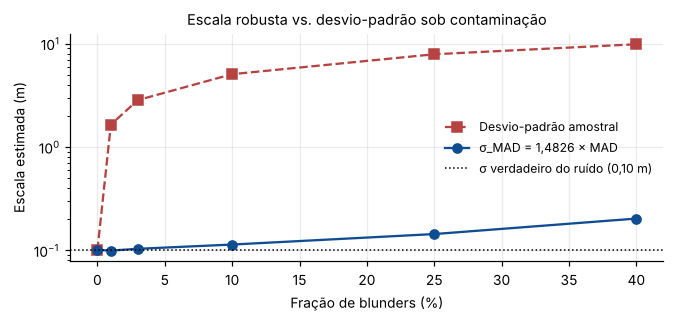

In [2]:
rng = np.random.default_rng(1)
n = 2000
linhas = []
for frac in [0.0, 0.01, 0.03, 0.10, 0.25, 0.40]:
    r = rng.normal(0.0, 0.10, n)
    k = int(frac * n)
    r[:k] += rng.choice([-1, 1], k) * rng.uniform(5, 25, k)      # blunders de 5–25 m
    sigma_mad = 1.4826 * np.median(np.abs(r - np.median(r)))
    linhas.append({"Contaminação (%)": 100 * frac, "Média (m)": r.mean(), "Mediana (m)": np.median(r),
                   "Desvio-padrão (m)": r.std(), "σ_MAD (m)": sigma_mad})
tab_rob = pd.DataFrame(linhas).set_index("Contaminação (%)")

fig, ax = plt.subplots(figsize=(6.2, 3.0))
ax.plot(tab_rob.index, tab_rob["Desvio-padrão (m)"], "s--", color="#B64342", label="Desvio-padrão amostral")
ax.plot(tab_rob.index, tab_rob["σ_MAD (m)"], "o-", color="#0F4D92", label="σ_MAD = 1,4826 × MAD")
ax.axhline(0.10, color="k", ls=":", lw=1, label="σ verdadeiro do ruído (0,10 m)")
ax.set_yscale("log"); ax.set_xlabel("Fração de blunders (%)"); ax.set_ylabel("Escala estimada (m)")
ax.set_title("Escala robusta vs. desvio-padrão sob contaminação"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
tab_rob.round(3)

**Leitura do resultado.**
- Com apenas **1% de blunders** o desvio-padrão já está inflado em mais de uma ordem de grandeza; um limiar "$3\sigma$" calculado com ele não rejeitaria nenhum blunder.
- O $\sigma_{\text{MAD}}$ permanece próximo de $0{,}10\text{ m}$ até contaminações altas: ele "enxerga" o ruído da superfície, não os erros grosseiros. Acima de ~25–40% de contaminação até o MAD começa a ceder — por isso os filtros nativos do ATL06 (Caderno 01) removem primeiro o grosso dos problemas.

**No pipeline.** Filtro along-track `thwaites.qc.filttrack` (Caderno 01), rejeição iterativa do ajuste `fitsec` em `thwaites.timeseries.dhdt` (Caderno 03), `robust_line` do ApRES (Caderno 07).

### 2.2 Tendência Monotônica: Mann–Kendall e Declive de Theil–Sen

**Problema.** Com 7 anos de dados, uma única temporada ruim (cobertura parcial, neve soprada) pesa muito numa regressão linear por mínimos quadrados (OLS).

**Ideia.** O teste de Mann–Kendall usa apenas o **sinal** das diferenças entre todos os pares de épocas, $S = \sum_{i<j}\operatorname{sgn}(y_j - y_i)$; o declive de Theil–Sen é a **mediana** das inclinações par a par, $\hat\beta = \operatorname{med}_{i<j}\,(y_j-y_i)/(t_j-t_i)$. Ambos são insensíveis a valores extremos isolados e não supõem normalidade.

**Aplicação 1 — dado real.** Série de 13 temporadas da célula de 5 km do núcleo de afinamento da Thwaites (`celula_nucleo_thwaites_serie.csv`, Caderno 04). **Aplicação 2 — robustez.** A mesma série com a **última** temporada corrompida artificialmente em $+8\text{ m}$ (pontos nas extremidades têm a maior alavanca sobre o OLS):

,OLS (m/ano),Theil–Sen (m/ano),IC95% Sen,τ de Kendall,p (Mann–Kendall),Veredito
Série,,,,,,
Série real,-4.2577,-4.3456,[-4.59; -4.09],-1.0000,0.0,decrescente
Série com 1 temporada corrompida,-3.7253,-4.3406,[-4.59; -3.92],-0.8974,0.0,decrescente


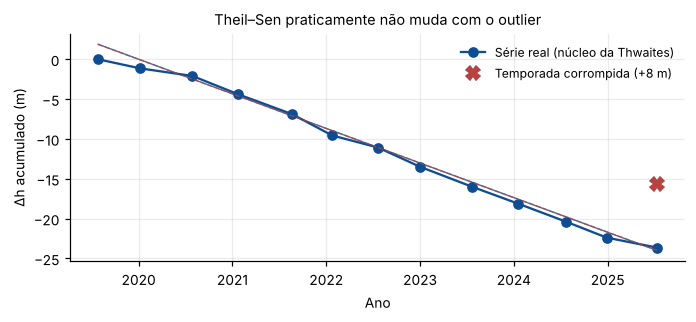

In [3]:
from thwaites.stats import mann_kendall_sen

nucleo = pd.read_csv(DATA_DIR / "celula_nucleo_thwaites_serie.csv")
t_n = nucleo["t_center_year"].to_numpy()
y_n = nucleo["dh_ice_m"].to_numpy()

y_bad = y_n.copy()
y_bad[-1] += 8.0                    # última temporada (JJA 2025) corrompida em +8 m

linhas = []
for rotulo, yy in [("Série real", y_n), ("Série com 1 temporada corrompida", y_bad)]:
    mk = mann_kendall_sen(t_n, yy)
    ols = np.polyfit(t_n, yy, 1)[0]
    linhas.append({"Série": rotulo, "OLS (m/ano)": ols, "Theil–Sen (m/ano)": mk["sens_slope"],
                   "IC95% Sen": f"[{mk['sens_lo']:.2f}; {mk['sens_hi']:.2f}]",
                   "τ de Kendall": mk["tau"], "p (Mann–Kendall)": mk["p_value"], "Veredito": mk["trend"]})

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(t_n, y_n, "o-", color="#0F4D92", label="Série real (núcleo da Thwaites)")
ax.plot(t_n[-1], y_bad[-1], "X", color="#B64342", ms=9, label="Temporada corrompida (+8 m)")
for yy, cor, ls in [(y_n, "#0F4D92", "-"), (y_bad, "#B64342", "--")]:
    mk = mann_kendall_sen(t_n, yy)
    ax.plot(t_n, mk["intercept"] + mk["sens_slope"] * t_n, ls, color=cor, lw=0.9, alpha=0.8)
ax.set_xlabel("Ano"); ax.set_ylabel("Δh acumulado (m)")
ax.set_title("Theil–Sen praticamente não muda com o outlier")
ax.legend(frameon=False, fontsize=8); plt.tight_layout()
pd.DataFrame(linhas).set_index("Série").round(4)

**Leitura do resultado.**
- Na série real, Theil–Sen e OLS concordam (≈ $-4{,}3\text{ m/ano}$) e $\tau \approx -1$: **todas** as temporadas estão abaixo da anterior, a tendência é inequívoca.
- Com a última temporada corrompida, o OLS é puxado em direção a zero, enquanto o Theil–Sen quase não se altera: a mediana de 78 inclinações par a par ignora as poucas inclinações contaminadas. O $p$ de Mann–Kendall continua minúsculo porque só os pares que envolvem o ponto ruim mudam de sinal.
- **Cuidado:** o $p$ de Mann–Kendall supõe épocas independentes. Para séries autocorrelacionadas use a versão sazonal (`seasonal_mann_kendall_sen`, compara apenas a mesma estação) ou corrija os graus de liberdade (Seção 2.6).

**No pipeline.** `thwaites.timeseries.trend` (tendência por nó, Caderno 03) e a célula do núcleo da Thwaites (Caderno 04).

### 2.3 Milhares de Testes Simultâneos: Controle da Taxa de Falsas Descobertas (FDR)

**Problema.** O domínio apoiado tem ~7.000 nós. Testando cada um a $\alpha = 5\%$, esperam-se ~350 "tendências significativas" **mesmo que nada mude**.

**Ideia.** O procedimento de Benjamini–Hochberg ordena os $p$-valores e rejeita os $k$ menores tais que $p_{(k)} \le (k/N)\,\alpha$. Ele não controla a chance de *um* falso positivo (Bonferroni, muito conservador), mas a **fração esperada de falsos entre as descobertas**, $\mathbb{E}[V/R] \le \alpha$ — o que interessa ao mapear onde há afinamento.

**Aplicação.** 7.000 nós sintéticos, dos quais 15% têm afinamento real:

In [4]:
from scipy.stats import norm
from thwaites.stats import benjamini_hochberg_fdr

rng = np.random.default_rng(7)
n_nos = 7000
real = rng.random(n_nos) < 0.15                      # 15% dos nós com sinal verdadeiro
z = rng.normal(0, 1, n_nos) + np.where(real, -3.0, 0.0)
p = 2 * norm.sf(np.abs(z))

rej_bh, p_adj = benjamini_hochberg_fdr(p, alpha=0.05)
rej_ing = p < 0.05
rej_bonf = p < 0.05 / n_nos

def resumo(rej, nome):
    return {"Critério": nome, "Descobertas": int(rej.sum()), "Falsas descobertas": int((rej & ~real).sum()),
            "Fração falsa (FDP, %)": 100 * (rej & ~real).sum() / max(rej.sum(), 1),
            "Sinais reais encontrados (%)": 100 * (rej & real).sum() / real.sum()}

pd.DataFrame([resumo(rej_ing, "p < 0,05 em cada nó (ingênuo)"),
              resumo(rej_bonf, "Bonferroni (p < 0,05/N)"),
              resumo(rej_bh, "Benjamini–Hochberg (FDR 5%)")]).set_index("Critério").round(1)

,Descobertas,Falsas descobertas,"Fração falsa (FDP, %)",Sinais reais encontrados (%)
Critério,,,,
"p < 0,05 em cada nó (ingênuo)",1200,308,25.7,86.8
"Bonferroni (p < 0,05/N)",65,0,0.0,6.3
Benjamini–Hochberg (FDR 5%),654,29,4.4,60.8


**Leitura do resultado.**
- O critério ingênuo encontra quase todos os sinais reais, mas ~300 nós sem mudança entram no mapa como "significativos".
- Bonferroni elimina os falsos, porém descarta grande parte do sinal verdadeiro (perde poder).
- Benjamini–Hochberg mantém a fração de falsas descobertas perto dos 5% nominais e ainda recupera a maioria dos sinais reais — é o compromisso adequado para mapas.
- Sob autocorrelação espacial positiva (PRDS) o BH continua válido (Benjamini & Yekutieli, 2001), mas o número *efetivo* de testes independentes é bem menor que o número de nós (ver Seção 2.10).

**No pipeline.** `thwaites.stats.trend_tests.benjamini_hochberg_fdr`, aplicado às tendências nodais (Caderno 03) e aos 25 testes ENSO × defasagem (Caderno 09).

### 2.4 Incerteza com Dados Agrupados: Jackknife *Leave-One-Year-Out*

**Problema.** Um nó reúne $10^4$–$10^5$ segmentos, mas eles vêm de apenas ~7 invernos. Segmentos do mesmo ano compartilham a mesma anomalia de acumulação de neve, o mesmo estado do firn e a mesma maré. O erro formal do OLS, $\sigma \propto N_{\text{seg}}^{-1/2}$, trata cada segmento como independente e fica **otimista**.

**Ideia.** Tratar o **ano** como unidade amostral: reajustar o modelo omitindo um ano inteiro por vez e medir a dispersão das réplicas:
$$\operatorname{Var}_{\text{JK}}(\hat\theta) = \frac{k-1}{k}\sum_{y=1}^{k}\left(\hat\theta_{(-y)} - \bar\theta_{(\cdot)}\right)^2$$

**Aplicação.** Nó sintético com afinamento de $-0{,}30\text{ m/ano}$, 400 segmentos por inverno e anomalias interanuais de amplitude crescente:

In [5]:
from thwaites.timeseries.uncertainty import jackknife_rate_uncertainty

anos = np.arange(2019, 2026)
linhas = []
for sigma_ano in [0.0, 0.05, 0.10, 0.25, 0.50]:
    rng = np.random.default_rng(3)
    t = np.concatenate([a + 0.45 + rng.uniform(0, 0.2, 400) for a in anos])   # janelas JJA
    ano_idx = np.floor(t).astype(int) - anos[0]
    anomalia = rng.normal(0, sigma_ano, anos.size)                            # comum a todo o ano
    dx = rng.uniform(-15e3, 15e3, t.size); dy = rng.uniform(-15e3, 15e3, t.size)
    h = -0.30 * (t - 2022) + 2e-4 * dx - 1e-4 * dy + anomalia[ano_idx] + rng.normal(0, 0.30, t.size)
    taxa, se_jk, k, se_formal = jackknife_rate_uncertainty(t, h, dx, dy, t_ref=2022.0)
    linhas.append({"σ da anomalia interanual (m)": sigma_ano, "dh/dt estimado (m/ano)": taxa,
                   "Erro formal OLS (m/ano)": se_formal, "Erro jackknife por ano (m/ano)": se_jk,
                   "Inflação (JK / formal)": se_jk / se_formal,
                   "Erro verdadeiro |dh/dt + 0,30|": abs(taxa + 0.30)})
pd.DataFrame(linhas).set_index("σ da anomalia interanual (m)").round(4)

,dh/dt estimado (m/ano),Erro formal OLS (m/ano),Erro jackknife por ano (m/ano),Inflação (JK / formal),"Erro verdadeiro |dh/dt + 0,30|"
σ da anomalia interanual (m),,,,,
0.00,-0.2987,0.0028,0.0052,1.8315,0.0013
0.05,-0.2933,0.0029,0.0112,3.8861,0.0067
0.10,-0.2879,0.0030,0.0260,8.7386,0.0121
0.25,-0.2716,0.0036,0.0710,19.5339,0.0284
0.50,-0.2444,0.0054,0.1463,27.0771,0.0556


**Leitura do resultado.**
- Sem anomalia interanual (primeira linha), formal e jackknife são da mesma ordem: o jackknife não "inventa" incerteza.
- Quando existe sinal comum a cada ano — situação real do firn antártico — o erro formal quase não muda (ele só enxerga os 2.800 segmentos), enquanto o jackknife cresce na proporção certa. Compare a coluna do erro verdadeiro: ele é da ordem do erro jackknife, não do formal.
- No produto real, a inflação mediana é de **$\sim 92\times$** no gelo apoiado (Caderno 04): reportar o erro formal faria quase qualquer nó parecer significativo.

**No pipeline.** `thwaites.timeseries.uncertainty.jackknife_rate_uncertainty` (todos os nós dh/dt) e o *Delete-a-Group Jackknife* por passagens orbitais nas plataformas (`thwaites.stats.resampling.delete_group_jackknife`, Caderno 06).

### 2.5 Separar Maré de Topografia Móvel: Complemento de Schur e Erro Agrupado CR1

**Problema.** Para medir a resposta à maré $\beta$ (Caderno 05) ajusta-se $\mathbf{h} = \mathbf{X}\boldsymbol\alpha + \mathbf{z}\beta + \boldsymbol\varepsilon$: $\mathbf{X}$ contém milhares de parâmetros locais de topografia e tendência (um bloco por célula material) e $\mathbf{z}$ é a maré predita. Resolver tudo junto é caro; ajustar em sequência (*backfitting* — primeiro a topografia, depois a maré no resíduo) é barato mas **enviesado**.

**Ideia (Frisch–Waugh–Lovell).** Antes de estimar $\beta$, remove-se de $\mathbf{z}$ *e* de $\mathbf{h}$ tudo o que a topografia local explica, com o projetor $\mathbf{M}_X = \mathbf{I} - \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T$ (calculado célula a célula, porque $\mathbf{X}^T\mathbf{X}$ é bloco-diagonal):
$$\hat\beta = \frac{\tilde{\mathbf{z}}^T\tilde{\mathbf{h}}}{\tilde{\mathbf{z}}^T\tilde{\mathbf{z}}}, \qquad \tilde{\mathbf{z}} = \mathbf{M}_X\mathbf{z},\; \tilde{\mathbf{h}} = \mathbf{M}_X\mathbf{h}$$
O *backfitting* divide por $\mathbf{z}^T\mathbf{z}$ em vez de $\tilde{\mathbf{z}}^T\tilde{\mathbf{z}}$ e por isso **atenua** $\beta$ pelo fator $\tilde{\mathbf{z}}^T\tilde{\mathbf{z}} / \mathbf{z}^T\mathbf{z} < 1$.

Como a maré e o erro de uma mesma passagem orbital são compartilhados por todos os seus segmentos, o erro-padrão usa o sanduíche agrupado por passagem (CR1): $\widehat{\operatorname{Var}}(\hat\beta) = \frac{G}{G-1}\,\frac{\sum_g (\sum_{i\in g}\tilde z_i \hat e_i)^2}{(\tilde{\mathbf{z}}^T\tilde{\mathbf{z}})^2}$.

**Aplicação.** Monte Carlo com 30 células materiais (100 segmentos cada, 5 parâmetros locais por célula) e maré/erro constantes dentro de cada passagem (como no dado real), $\beta_{\text{verdadeiro}} = 0{,}90$:

Fator de atenuação previsto  z̃ᵀz̃ / zᵀz  = 0.939  ->  0,90 × fator = 0.845
Média observada do backfitting           = 0.841


,Cobertura CR1 (%),Cobertura OLS (%)
Passagens G,,
20,83.0,8.7
60,90.7,24.7
200,93.0,43.0


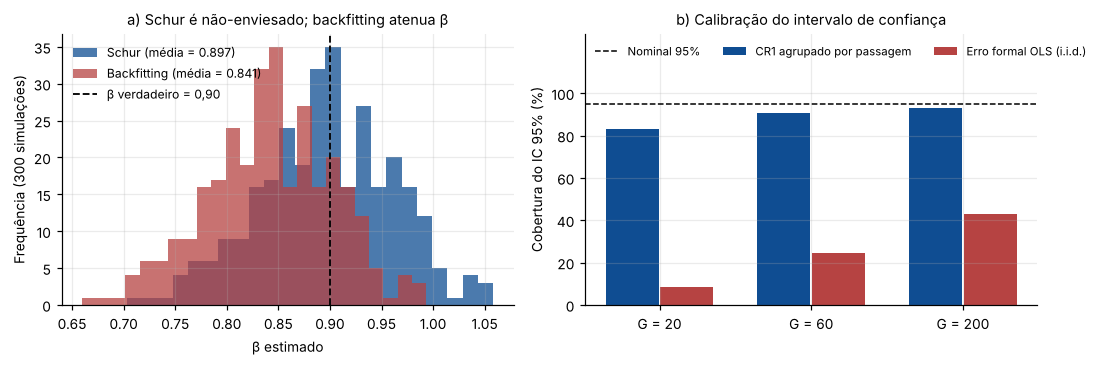

In [6]:
from thwaites.stats import schur_complement_beta, cr1_clustered_se

def simula_mare(n_passagens, n_rep=300, seed=20261120):
    rng = np.random.default_rng(seed)
    n_cel, n_por_cel = 30, 100
    n = n_cel * n_por_cel
    celula = np.repeat(np.arange(n_cel), n_por_cel)
    passagem = rng.integers(0, n_passagens, n)
    t = np.sort(rng.uniform(-3, 3, n_passagens))[passagem]                 # época de cada passagem
    mare = rng.normal(0, 0.6, n_passagens)[passagem] + rng.normal(0, 0.03, n)
    X = np.c_[np.ones(n), rng.uniform(-1, 1, n), t, np.sin(2 * np.pi * t), np.cos(2 * np.pi * t)]
    est = {"schur": [], "backfit": [], "cob_cr1": [], "cob_ols": [], "atenuacao": []}
    for _ in range(n_rep):
        alpha = rng.normal(0, 3.0, (n_cel, X.shape[1]))
        erro = rng.normal(0, 0.30, n_passagens)[passagem] + rng.normal(0, 0.05, n)
        h = np.einsum("ij,ij->i", X, alpha[celula]) + 0.90 * mare + erro
        b, H, z_proj, res = schur_complement_beta(X, celula, mare, h)
        se_cr1, _ = cr1_clustered_se(z_proj, res, passagem, H)
        se_ols = np.sqrt(np.sum(res**2) / (n - n_cel * X.shape[1] - 1) / H)
        h_proj = z_proj * b + res                                          # = M_X h
        est["schur"].append(b)
        est["backfit"].append((mare @ h_proj) / (mare @ mare))             # regressão do resíduo na maré crua
        est["atenuacao"].append(H / (mare @ mare))
        est["cob_cr1"].append(abs(b - 0.90) <= 1.96 * se_cr1)
        est["cob_ols"].append(abs(b - 0.90) <= 1.96 * se_ols)
    return {k: np.asarray(v) for k, v in est.items()}

sim = simula_mare(60)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4))
ax[0].hist(sim["schur"], bins=24, alpha=0.75, color="#0F4D92", label=f"Schur (média = {sim['schur'].mean():.3f})")
ax[0].hist(sim["backfit"], bins=24, alpha=0.75, color="#B64342", label=f"Backfitting (média = {sim['backfit'].mean():.3f})")
ax[0].axvline(0.90, color="k", ls="--", lw=1.2, label="β verdadeiro = 0,90")
ax[0].set_xlabel("β estimado"); ax[0].set_ylabel("Frequência (300 simulações)")
ax[0].set_title("a) Schur é não-enviesado; backfitting atenua β"); ax[0].legend(frameon=False, fontsize=8)

cob = []
for G in [20, 60, 200]:
    s = sim if G == 60 else simula_mare(G)
    cob.append({"Passagens G": G, "Cobertura CR1 (%)": 100 * s["cob_cr1"].mean(), "Cobertura OLS (%)": 100 * s["cob_ols"].mean()})
cob = pd.DataFrame(cob).set_index("Passagens G")
xg = np.arange(len(cob))
ax[1].bar(xg - 0.18, cob["Cobertura CR1 (%)"], 0.35, color="#0F4D92", label="CR1 agrupado por passagem")
ax[1].bar(xg + 0.18, cob["Cobertura OLS (%)"], 0.35, color="#B64342", label="Erro formal OLS (i.i.d.)")
ax[1].axhline(95, color="k", ls="--", lw=1, label="Nominal 95%")
ax[1].set_xticks(xg); ax[1].set_xticklabels([f"G = {g}" for g in cob.index])
ax[1].set_ylabel("Cobertura do IC 95% (%)"); ax[1].set_ylim(0, 128); ax[1].set_yticks(range(0, 101, 20))
ax[1].set_title("b) Calibração do intervalo de confiança"); ax[1].legend(frameon=False, fontsize=7.5, loc="upper left", ncol=3)
plt.tight_layout()

print(f"Fator de atenuação previsto  z̃ᵀz̃ / zᵀz  = {sim['atenuacao'].mean():.3f}  ->  0,90 × fator = {0.90 * sim['atenuacao'].mean():.3f}")
print(f"Média observada do backfitting           = {sim['backfit'].mean():.3f}")
cob.round(1)

**Leitura do resultado.**
- **Viés:** o complemento de Schur recupera $\beta = 0{,}90$ em média; o *backfitting* fica sistematicamente abaixo, e a atenuação observada coincide com o fator teórico $\tilde{\mathbf{z}}^T\tilde{\mathbf{z}}/\mathbf{z}^T\mathbf{z}$ impresso acima. Em dados reais esse viés "achata" a curva $\beta(x)$ e desloca a zona de flexão.
- **Incerteza:** o erro formal OLS produz intervalos estreitos demais (cobertura muito abaixo de 95%), porque conta como independentes segmentos que compartilham o erro da passagem — e piora quanto menos passagens existem. O CR1 converge para o nominal à medida que o número de passagens $G$ cresce; com poucas passagens ($G \approx 20$) ele ainda é liberal, uma limitação conhecida do estimador sanduíche com poucos *clusters* (Cameron & Miller, 2015). Nesse regime, um *wild cluster bootstrap* seria a alternativa.
- Nas plataformas da ASE há centenas de passagens por faixa de distância, o regime em que o CR1 é bem calibrado.

**No pipeline.** `thwaites.stats.panel_schur` em `run_tide_response_lagrangian.py` (Caderno 05) e, com indicadores de época no lugar da maré, na série de espessura por efeitos fixos (`fixed_effects_panel_series`, Caderno 06).

### 2.6 Correlação entre Séries Curtas e Suavizadas: $N_{\text{ef}}$ e Substitutas de Fourier

**Problema.** Para testar se o derretimento basal acompanha o ENSO, as anomalias trimestrais (~24 pontos) são destendenciadas e suavizadas por média móvel de 4 trimestres. A suavização cria **memória**: pontos vizinhos deixam de ser independentes e o teste $t$ usual, com $N-2$ graus de liberdade, acusa correlações significativas com frequência muito maior que 5%.

**Ideia.**
- *Graus de liberdade efetivos:* $N_{\text{ef}} = N \big/ \left[1 + 2\sum_k (1 - k/N)\,\rho_a(k)\rho_b(k)\right]$ (Pyper & Peterman, 1998), que se reduz a $N(1-\phi_a\phi_b)/(1+\phi_a\phi_b)$ para processos AR(1) (Bretherton et al., 1999).
- *Substitutas de fase de Fourier:* gera-se uma série com **o mesmo espectro de potência** (mesma memória) mas fases aleatórias, o que destrói qualquer relação com a outra série. Repetindo 2.000 vezes obtém-se a distribuição nula de $r$ sob a memória real dos dados (Theiler et al., 1992; Ebisuzaki, 1997).

**Aplicação 1 — um caso.** Duas séries AR(1) **independentes** ($\phi = 0{,}6$, $N = 24$):

,Valor
r de Pearson,0.566
N (pontos após suavizar),21.000
N_ef AR(1) — Bretherton,4.744
N_ef multi-lag — Pyper–Peterman,7.301
p do teste t ingênuo (gl = N−2),0.007
p das substitutas de Fourier,0.190


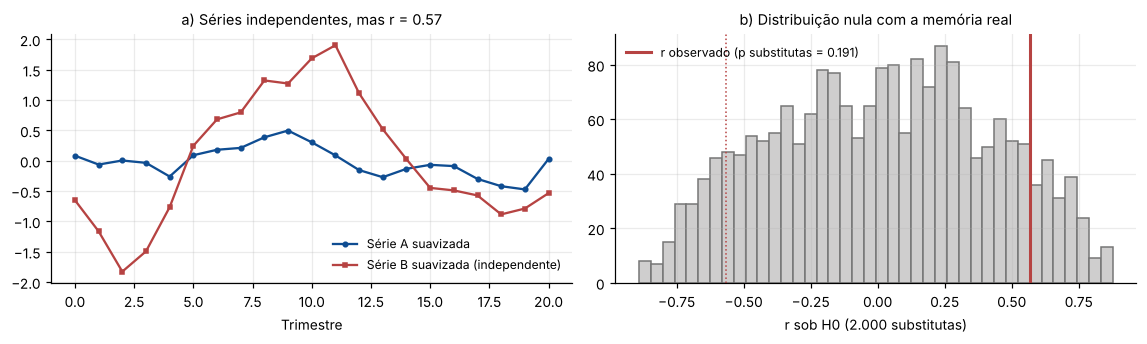

In [7]:
from scipy.stats import t as student_t
from thwaites.stats import (bretherton_effective_dof, fourier_phase_surrogate,
                            pyper_peterman_effective_dof, surrogate_correlation_test)

def ar1(n, phi, rng):
    x = np.zeros(n)
    for k in range(1, n):
        x[k] = phi * x[k - 1] + rng.normal()
    t_idx = np.arange(n, dtype=float)
    return x - np.polyval(np.polyfit(t_idx, x, 1), t_idx)      # destendenciada

def media_movel(v, w=4):
    return np.convolve(v, np.ones(w) / w, mode="valid")

rng = np.random.default_rng(1)
a, b = ar1(24, 0.6, rng), ar1(24, 0.6, rng)
res = surrogate_correlation_test(a, b, smooth_window=4, n_surrogates=2000, seed=5)
p_ingenuo = 2 * student_t.sf(abs(res["r"]) * np.sqrt((res["n"] - 2) / (1 - res["r"]**2)), df=res["n"] - 2)

# distribuição nula das substitutas (para o gráfico)
rng_s = np.random.default_rng(5)
b_sm = media_movel(b)
r_nulo = [np.corrcoef(media_movel(fourier_phase_surrogate(a, rng_s)), b_sm)[0, 1] for _ in range(2000)]

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
ax[0].plot(media_movel(a), "o-", color="#0F4D92", ms=3, label="Série A suavizada")
ax[0].plot(b_sm, "s-", color="#B64342", ms=3, label="Série B suavizada (independente)")
ax[0].set_xlabel("Trimestre"); ax[0].set_title(f"a) Séries independentes, mas r = {res['r']:.2f}")
ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(r_nulo, bins=40, color="#CFCECE", edgecolor="#767676")
ax[1].axvline(res["r"], color="#B64342", lw=2, label=f"r observado (p substitutas = {res['p_surrogate']:.3f})")
ax[1].axvline(-res["r"], color="#B64342", lw=1, ls=":")
ax[1].set_xlabel("r sob H0 (2.000 substitutas)"); ax[1].set_title("b) Distribuição nula com a memória real")
ax[1].legend(frameon=False, fontsize=8); plt.tight_layout()

pd.Series({"r de Pearson": res["r"], "N (pontos após suavizar)": res["n"],
           "N_ef AR(1) — Bretherton": res["n_eff_ar1"], "N_ef multi-lag — Pyper–Peterman": res["n_eff_pp"],
           "p do teste t ingênuo (gl = N−2)": p_ingenuo, "p das substitutas de Fourier": res["p_surrogate"]}).round(3).to_frame("Valor")

**Leitura do caso.** As duas séries foram geradas independentemente; ainda assim, depois da suavização, a correlação parece forte e o teste $t$ ingênuo a declara significativa. O número efetivo de amostras é bem menor que $N$ e a distribuição nula das substitutas é larga: correlações dessa magnitude ocorrem por acaso com frequência alta. **Uma correlação alta entre séries curtas e suavizadas não é, por si só, evidência de acoplamento.**

**Aplicação 2 — calibração.** Repetindo o experimento 1.000 vezes sob $H_0$, quantas vezes cada método declara $p < 0{,}05$? (O ideal é 5%.)

In [8]:
rng = np.random.default_rng(999)
n_trials = 1000                      # ~40 s; reduza para 250 numa leitura rápida
fp = {"ingenuo": 0, "ar1": 0, "pp": 0, "surr": 0}
t_idx = np.arange(24, dtype=float)

for s in range(n_trials):
    u, v = np.zeros(24), np.zeros(24)
    for k in range(1, 24):                                   # duas AR(1) independentes, φ = 0,6
        u[k] = 0.6 * u[k - 1] + rng.normal()
        v[k] = 0.6 * v[k - 1] + rng.normal()
    u -= np.polyval(np.polyfit(t_idx, u, 1), t_idx)
    v -= np.polyval(np.polyfit(t_idx, v, 1), t_idx)
    res = surrogate_correlation_test(u, v, smooth_window=4, n_surrogates=200, seed=s + 1)
    r, n_obs = res["r"], res["n"]
    for chave, gl in [("ingenuo", n_obs - 2), ("ar1", max(res["n_eff_ar1"] - 2, 1)), ("pp", max(res["n_eff_pp"] - 2, 1))]:
        t_stat = abs(r) * np.sqrt(gl / max(1 - r**2, 1e-12))
        fp[chave] += 2 * student_t.sf(t_stat, df=gl) < 0.05
    fp["surr"] += res["p_surrogate"] < 0.05

ep = 100 * np.sqrt(0.05 * 0.95 / n_trials)
pd.DataFrame([
    {"Método (α nominal = 5%)": "Teste t ingênuo (gl = N − 2)", "Falsos positivos sob H0 (%)": 100 * fp["ingenuo"] / n_trials},
    {"Método (α nominal = 5%)": "Teste t com N_ef AR(1) — Bretherton et al. (1999)", "Falsos positivos sob H0 (%)": 100 * fp["ar1"] / n_trials},
    {"Método (α nominal = 5%)": "Teste t com N_ef multi-lag — Pyper & Peterman (1998)", "Falsos positivos sob H0 (%)": 100 * fp["pp"] / n_trials},
    {"Método (α nominal = 5%)": "Substitutas de fase de Fourier — Ebisuzaki (1997)", "Falsos positivos sob H0 (%)": 100 * fp["surr"] / n_trials},
]).set_index("Método (α nominal = 5%)").assign(**{"Erro Monte Carlo (±1σ, %)": ep}).round(1)

,Falsos positivos sob H0 (%),"Erro Monte Carlo (±1σ, %)"
Método (α nominal = 5%),,
Teste t ingênuo (gl = N − 2),42.1,0.7
Teste t com N_ef AR(1) — Bretherton et al. (1999),1.3,0.7
Teste t com N_ef multi-lag — Pyper & Peterman (1998),7.1,0.7
Substitutas de fase de Fourier — Ebisuzaki (1997),8.2,0.7


**Leitura da calibração.**
- O teste ingênuo erra em quase metade das vezes: é a origem de muitas "teleconexões" publicadas com séries curtas.
- A correção AR(1) vai para o outro extremo (conservadora demais): a média móvel cria correlação em vários *lags*, não só no primeiro.
- Pyper–Peterman e as substitutas de Fourier reduzem a taxa de falsos positivos de ~40% para perto do nominal, mas com $N \approx 21$ ambos ainda ficam um pouco acima de 5%. Consequência prática: um $p$ marginal ($\approx 0{,}05$) não deve ser lido como evidência. O estudo reporta **as duas** medidas e só aceita coerência quando ambas concordam — no Caderno 09, o único teste ENSO com $p < 0{,}05$ (PIG, lag 4, $p = 0{,}048$) é exatamente o tipo de resultado que essa calibração manda descartar.

**No pipeline.** `run_coherence_test_ase.py` (Caderno 09): coerência entre plataformas e com o índice ONI.

### 2.7 Os Anos Diferem Entre Si? Teste $Q$ de Cochran

**Problema.** As séries anuais de derretimento basal oscilam. A oscilação é real ou cabe no erro de medida?

**Ideia.** Sob $H_0$ (taxa constante), cada ano $y_t$ difere da média ponderada $\hat\mu_w = \sum w_t y_t / \sum w_t$ ($w_t = \sigma_t^{-2}$) apenas por ruído, e
$$Q = \sum_t \left(\frac{y_t - \hat\mu_w}{\sigma_t}\right)^2 \sim \chi^2_{K-1}.$$
Regra prática: $Q/(K-1) \approx 1$ → dispersão compatível com o erro; $Q/(K-1) \gg 1$ → variabilidade real; $Q/(K-1) \ll 1$ → os erros declarados provavelmente estão superestimados.

**Aplicação — dado real.** Recalculamos o teste diretamente das séries anuais disjuntas (`serie_anual_independente_mb.csv`) e conferimos com a tabela publicada pelo pipeline (`teste_chi2_variabilidade_anual.csv`):

,Média ponderada (m/ano),Q,gl,Q / gl,p,Q publicado
unidade,,,,,,
Cosgrove,0.3776,13.3629,6,2.2271,0.0376,13.3629
Crosson,8.3257,2.1764,6,0.3627,0.9028,2.1764
Dotson,6.5733,4.2126,6,0.7021,0.6479,4.2126
Pine_Island,8.8946,1.1689,6,0.1948,0.9784,1.1689
Thwaites_TEIS,4.5568,29.2928,6,4.8821,0.0001,29.2928
Thwaites_TWGT,42.3936,3.5041,6,0.5840,0.7434,3.5041


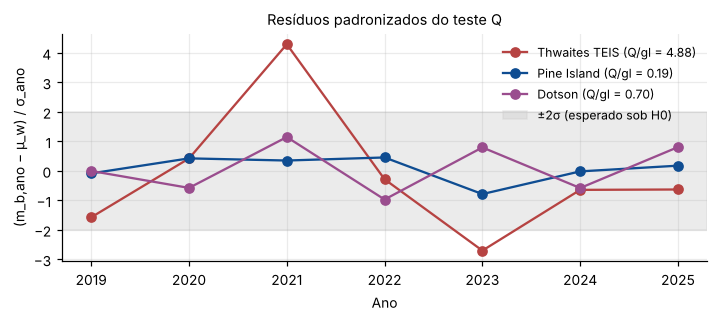

In [9]:
from thwaites.stats import cochran_interannual_chi2

anual = pd.read_csv(DATA_DIR / "serie_anual_independente_mb.csv")
publicado = pd.read_csv(DATA_DIR / "teste_chi2_variabilidade_anual.csv").set_index("unidade")

linhas = []
for u, g in anual.groupby("unidade", sort=False):
    q = cochran_interannual_chi2(g["mb_mpa"], g["se_mpa"])
    linhas.append({"unidade": u, "Média ponderada (m/ano)": q["weighted_mean"], "Q": q["chi2"], "gl": q["dof"],
                   "Q / gl": q["chi2"] / q["dof"], "p": q["p_value"], "Q publicado": publicado.loc[u, "chi2"]})
tab_q = pd.DataFrame(linhas).set_index("unidade")

fig, ax = plt.subplots(figsize=(6.6, 3.0))
for u in ["Thwaites_TEIS", "Pine_Island", "Dotson"]:
    g = anual[anual["unidade"] == u]
    zres = (g["mb_mpa"] - tab_q.loc[u, "Média ponderada (m/ano)"]) / g["se_mpa"]
    ax.plot(g["ano"], zres, "o-", color=CORES[u], label=f"{u.replace('_', ' ')} (Q/gl = {tab_q.loc[u, 'Q / gl']:.2f})")
ax.axhspan(-2, 2, color="#CFCECE", alpha=0.4, label="±2σ (esperado sob H0)")
ax.set_xlabel("Ano"); ax.set_ylabel("(m_b,ano − μ_w) / σ_ano")
ax.set_title("Resíduos padronizados do teste Q"); ax.legend(frameon=False, fontsize=8); plt.tight_layout()
tab_q.round(4)

**Leitura do resultado.**
- O recálculo reproduz exatamente a coluna publicada — a tabela do Caderno 09 é reprodutível a partir das séries anuais.
- **TEIS:** $Q/\text{gl} \approx 5$ e $p \approx 5\times10^{-5}$ — vários anos saem da faixa de $\pm 2\sigma$; a variabilidade interanual é real.
- **Pine Island:** $Q/\text{gl} \approx 0{,}2$ — os anos variam *menos* do que os erros declarados permitiriam. Não é evidência de constância "perfeita", e sim de que $\sigma_t$ é conservador (dominado pela incerteza de agregação, Caderno 06).
- O teste só é válido porque os anos são **disjuntos** (cada ano usa só suas 4 estações). Com janelas móveis sobrepostas, $Q$ seria inflado artificialmente.

**No pipeline.** `run_annual_mb_v2.py` (Caderno 09, Hipótese 1).

### 2.8 Mudança Abrupta ou Tendência Contínua? Comparação de Modelos por $\Delta\text{BIC}$

**Problema.** Uma queda observada numa série pode ser um degrau (evento discreto, como a evacuação do mélange em 2024) ou apenas uma tendência gradual amostrada de forma irregular.

**Ideia.** Ajustam-se os dois modelos e compara-se o critério de informação bayesiano $\text{BIC} = n\ln(\text{RSS}/n) + k\ln n$, que penaliza o parâmetro extra do degrau (a data da quebra). Pela escala de Kass & Raftery (1995): $\Delta\text{BIC} = \text{BIC}_{\text{reta}} - \text{BIC}_{\text{degrau}}$ entre 2–6 é evidência positiva, 6–10 forte e $>10$ muito forte a favor do degrau; valores negativos favorecem a reta.

**Aplicação.** Duas séries sintéticas de 28 estações (mesmo tamanho da série do tronco da Thwaites):

,ΔBIC (reta − degrau),Data da quebra,Tamanho do degrau,Modelo preferido
Série,,,,
"Degrau em 2024,1 (−0,155)",43.153,2024.125,-0.158,degrau
Tendência linear contínua,-25.888,2022.375,-0.090,reta


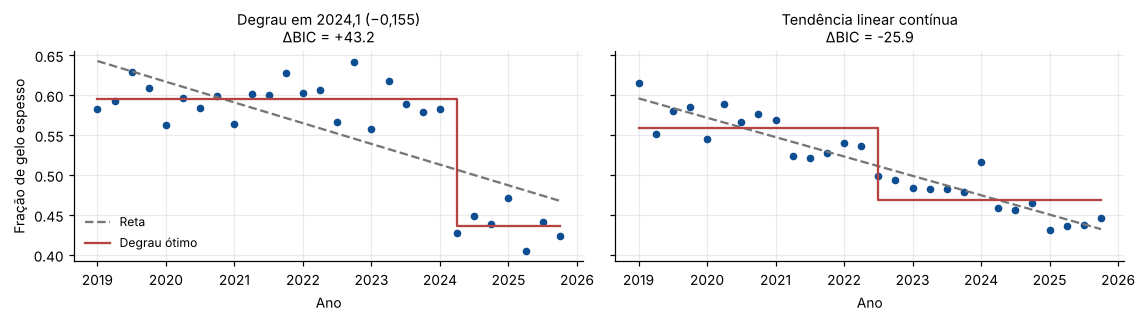

In [10]:
from thwaites.stats import step_change_bic_test

rng = np.random.default_rng(4)
t_ep = 2019 + 0.25 * np.arange(28)
series = {
    "Degrau em 2024,1 (−0,155)": np.where(t_ep < 2024.1, 0.596, 0.441) + rng.normal(0, 0.02, 28),
    "Tendência linear contínua":  0.60 - 0.025 * (t_ep - 2019) + rng.normal(0, 0.02, 28),
}
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.0), sharey=True)
linhas = []
for i, (nome, y) in enumerate(series.items()):
    r = step_change_bic_test(t_ep, y)
    linhas.append({"Série": nome, "ΔBIC (reta − degrau)": r["delta_bic"], "Data da quebra": r["best_break"],
                   "Tamanho do degrau": r["step_size"],
                   "Modelo preferido": "degrau" if r["delta_bic"] > 6 else ("reta" if r["delta_bic"] < -2 else "inconclusivo")})
    pre = t_ep < r["best_break"]
    ax[i].plot(t_ep, y, "o", color="#0F4D92", ms=4)
    ax[i].plot(t_ep, np.polyval(np.polyfit(t_ep, y, 1), t_ep), "--", color="#767676", label="Reta")
    ax[i].step(t_ep, np.where(pre, y[pre].mean(), y[~pre].mean()), where="post", color="#B64342", label="Degrau ótimo")
    ax[i].set_title(f"{nome}\nΔBIC = {r['delta_bic']:+.1f}"); ax[i].set_xlabel("Ano")
ax[0].set_ylabel("Fração de gelo espesso"); ax[0].legend(frameon=False, fontsize=8); plt.tight_layout()
pd.DataFrame(linhas).set_index("Série").round(3)

**Leitura do resultado.**
- Na série com degrau, $\Delta\text{BIC}$ é muito positivo e a data da quebra é recuperada no trimestre certo.
- Na série linear, o melhor degrau possível ainda deixa resíduos estruturados e $\Delta\text{BIC}$ é negativo: o teste **não** "encontra" degraus em tendências suaves.
- O $\Delta\text{BIC}$ diz *qual forma* descreve melhor a série, não se a mudança é grande. No estudo ele é combinado com o tamanho do degrau, o seu erro por jackknife ($z$) e a estabilidade da data nas réplicas (Caderno 09: $\Delta\text{BIC} = 32{,}8$, $z = 6{,}3$, mesma data em 99,8% das réplicas).

**No pipeline.** `thwaites.stats.time_series_tests.step_change_bic_test` — evento de 2024 no tronco oeste da Thwaites (Caderno 09).

### 2.9 Validar um Mapa Interpolado: Validação Cruzada Espacial em Blocos

**Problema.** As observações do ICESat-2 estão concentradas ao longo de trilhas; o mapa precisa prever valores **entre** trilhas, a quilômetros do dado mais próximo. Na validação cruzada aleatória, cada ponto de teste tem um vizinho de treino a ~20 m na mesma trilha, e o erro estimado sai muito otimista.

**Ideia.** Retirar **blocos espaciais inteiros** de lado $B$ em cada dobra (`spatial_block_assignments`), de modo que a distância entre teste e treino imite a distância real de predição.

**Aplicação.** Campo sintético suave amostrado por 25 trilhas; interpolação por IDW (`thwaites.interp.methods.idw_predict`). Comparamos o RMSE estimado por cada esquema com o **erro verdadeiro** fora das trilhas:

,RMSE estimado,Razão estimado / verdadeiro
Esquema de validação,,
K-fold aleatório (5 dobras),0.116,0.343
Blocos espaciais de 10 km,0.248,0.735
Blocos espaciais de 25 km,0.506,1.498
Blocos espaciais de 50 km,0.874,2.585
ERRO VERDADEIRO fora das trilhas,0.338,1.000


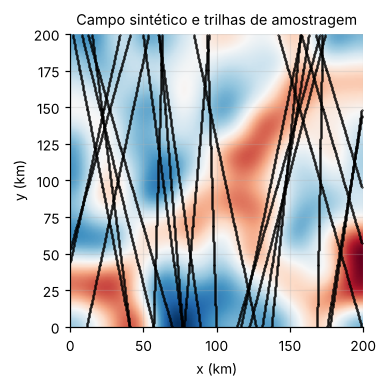

In [11]:
from scipy import ndimage
from thwaites.interp.methods import idw_predict
from thwaites.stats import spatial_block_assignments

rng = np.random.default_rng(0)
N = 200                                                      # grade de 200 × 200 km (pixel de 1 km)
campo = ndimage.gaussian_filter(rng.normal(size=(N, N)), 12); campo /= campo.std()
trilhas = []
for _ in range(25):
    x0, ang = rng.uniform(0, N * 1e3), rng.uniform(-0.3, 0.3)
    yy = np.linspace(0, (N - 1) * 1e3, 300); xx = x0 + np.tan(ang) * (yy - 1e5)
    ok = (xx >= 0) & (xx < (N - 1) * 1e3)
    trilhas.append(np.c_[xx[ok], yy[ok]])
P = np.vstack(trilhas)
ix, iy = (P[:, 0] / 1e3).astype(int), (P[:, 1] / 1e3).astype(int)
v = campo[iy, ix] + rng.normal(0, 0.1, len(P))

def rmse_cv(dobras):
    err = np.empty(len(v))
    for f in np.unique(dobras):
        te = dobras == f
        err[te] = idw_predict(P[~te, 0], P[~te, 1], v[~te], P[te, 0], P[te, 1])[0] - v[te]
    return float(np.sqrt(np.mean(err**2)))

linhas = [{"Esquema de validação": "K-fold aleatório (5 dobras)", "RMSE estimado": rmse_cv(rng.integers(0, 5, len(v)))}]
for B in [10e3, 25e3, 50e3]:
    linhas.append({"Esquema de validação": f"Blocos espaciais de {B/1e3:.0f} km",
                   "RMSE estimado": rmse_cv(spatial_block_assignments(P[:, 0], P[:, 1], B, n_folds=5, seed=0))})

# erro verdadeiro: prever o mapa inteiro em pixels sem observação
sem_obs = np.ones((N, N), bool); sem_obs[iy, ix] = False
gy, gx = np.nonzero(sem_obs); sel = rng.choice(gx.size, 3000, replace=False)
pred = idw_predict(P[:, 0], P[:, 1], v, gx[sel] * 1e3, gy[sel] * 1e3)[0]
erro_real = float(np.sqrt(np.mean((pred - campo[gy[sel], gx[sel]])**2)))
linhas.append({"Esquema de validação": "ERRO VERDADEIRO fora das trilhas", "RMSE estimado": erro_real})
tab_cv = pd.DataFrame(linhas).set_index("Esquema de validação")
tab_cv["Razão estimado / verdadeiro"] = tab_cv["RMSE estimado"] / erro_real

fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.imshow(campo, cmap="RdBu_r", origin="lower", extent=[0, N, 0, N])
ax.plot(P[:, 0] / 1e3, P[:, 1] / 1e3, ".", ms=0.8, color="k")
ax.set_title("Campo sintético e trilhas de amostragem"); ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)")
plt.tight_layout()
tab_cv.round(3)

**Leitura do resultado.**
- A validação aleatória subestima o erro real várias vezes: ela mede a capacidade de interpolar *ao longo* da trilha, não *entre* trilhas.
- Blocos de 10 km (comparáveis ao espaçamento entre trilhas) ficam muito mais próximos do erro verdadeiro, ainda um pouco otimistas; blocos de 25–50 km o superestimam, porque obrigam a prever a distâncias maiores do que as do mapa real. **O tamanho do bloco deve refletir a distância típica de predição** — e reportar a sensibilidade ao tamanho do bloco é mais honesto do que escolher um único valor (Caderno 04, painel b).
- A mesma lógica vale para a **calibração da variância**: além do RMSE, o estudo verifica se os resíduos padronizados $z = (\hat y - y)/\hat\sigma$ têm desvio-padrão ≈ 1 (`standardized_error_calibration`). No Caderno 03, a krigagem ordinária tem o menor RMSE e $z_{\text{std}} < 1$ (incerteza conservadora), enquanto os kernels gaussiano/mediana têm $z_{\text{std}} \approx 9$ (incerteza muito subestimada).

**No pipeline.** `thwaites.interp.select.cross_validate` (Cadernos 03 e 06) e `thwaites.uncertainty.error_correlation` (alcance $L$ dos resíduos, Caderno 04).

### 2.10 Somar Erros Correlacionados: Área de Correlação e Graus de Liberdade Espaciais

**Problema.** O balanço de massa soma ~8.000 células de 25 km². Se os erros fossem independentes, a incerteza da soma cairia com $\sqrt{N}$ e seria irrisória. Mas os erros altimétricos são correlacionados em dezenas de quilômetros (firn, acumulação, dinâmica), então células vizinhas erram juntas.

**Ideia (Rolstad et al., 2009).** Com desvio médio $\bar\sigma$ e comprimento de correlação $L$, a variância do volume integrado sobre a área $A$ é
$$\operatorname{Var}(\Delta V) \approx \bar\sigma^2\,A\,(\pi L^2) \quad\Longrightarrow\quad \sigma_M = \rho_{\text{gelo}}\,\bar\sigma\sqrt{A\,\pi L^2}, \qquad n_{\text{eff}} = \frac{A}{\pi L^2}.$$

**Aplicação — dado real.** Valores do balanço de massa DJF do gelo apoiado (`gelo_apoiado_balanco_massa_djf.json`):

Conferência: σ_M publicado para L = 34,1 km = 9.23 Gt/ano


,n_eff = A / (πL²),σ_M (Gt/ano)
L (km),,
5.0,2554.76,1.35
20.5,151.98,5.55
34.1,54.93,9.23
154.4,2.68,41.80


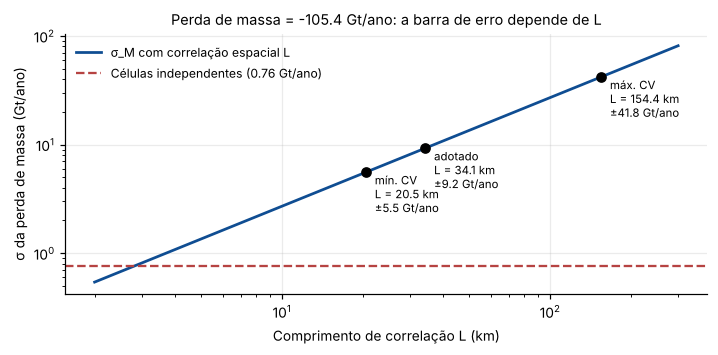

In [12]:
from thwaites.stats import rolstad_effective_samples

bm = json.loads((DATA_DIR / "gelo_apoiado_balanco_massa_djf.json").read_text(encoding="utf-8"))
A = bm["area_total_km2"] * 1e6
sig_bar = bm["sigma_dhdt_bar_m_yr"]
a_cel = bm["cell_area_km2"] * 1e6
para_gt = bm["ice_density"] / 1e12

L_km = np.geomspace(2, 300, 80)
sigma_L = sig_bar * np.sqrt(A * np.pi * (L_km * 1e3) ** 2) * para_gt
sigma_indep = sig_bar * np.sqrt(A * a_cel) * para_gt

fig, ax = plt.subplots(figsize=(6.6, 3.3))
ax.loglog(L_km, sigma_L, "-", color="#0F4D92", lw=1.8, label="σ_M com correlação espacial L")
ax.axhline(sigma_indep, color="#B64342", ls="--", label=f"Células independentes ({sigma_indep:.2f} Gt/ano)")
for L_marca, rot in [(20.5, "mín. CV"), (34.1, "adotado"), (154.4, "máx. CV")]:
    s = sig_bar * np.sqrt(A * np.pi * (L_marca * 1e3) ** 2) * para_gt
    ax.plot(L_marca, s, "o", color="k"); ax.annotate(f"{rot}\nL = {L_marca} km\n±{s:.1f} Gt/ano", (L_marca, s),
                                                       textcoords="offset points", xytext=(6, -26), fontsize=7.5)
ax.set_xlabel("Comprimento de correlação L (km)"); ax.set_ylabel("σ da perda de massa (Gt/ano)")
ax.set_title(f"Perda de massa = {bm['dMdt_Gt_yr']:.1f} Gt/ano: a barra de erro depende de L")
ax.legend(frameon=False, fontsize=8); plt.tight_layout()

linhas = []
for L_marca in [5.0, 20.5, 34.1, 154.4]:
    r = rolstad_effective_samples(A, L_marca * 1e3)
    linhas.append({"L (km)": L_marca, "n_eff = A / (πL²)": r["n_eff"],
                   "σ_M (Gt/ano)": sig_bar * np.sqrt(A * r["area_corr_m2"]) * para_gt})
print(f"Conferência: σ_M publicado para L = 34,1 km = {bm['sigma_dMdt_Gt_yr_correlated']:.2f} Gt/ano")
pd.DataFrame(linhas).set_index("L (km)").round(2)

**Leitura do resultado.**
- Tratar as células como independentes daria $\pm 0{,}8\text{ Gt/ano}$: uma precisão ilusória de <1% da perda de massa.
- Com o alcance $L = 34{,}1\text{ km}$ dos resíduos fora da amostra (Caderno 04), a incerteza sobe para $\pm 9{,}2\text{ Gt/ano}$, reproduzida exatamente aqui a partir da fórmula. Os 200 mil km² equivalem a apenas ~55 "amostras" independentes.
- A incerteza cresce linearmente com $L$: a **escolha de $L$ é a decisão mais importante do orçamento de erro**. Por isso o Caderno 04 mostra a sensibilidade completa ($L$ de 20,5 a 154,4 km → $\pm 5{,}5$ a $\pm 41{,}8\text{ Gt/ano}$) em vez de um único número.
- O mesmo raciocínio explica, no Caderno 02, por que a correlação $\text{dh/dt} \times$ velocidade ($r_s = -0{,}62$ em 8.656 nós) deixa de ser significativa: com $L = 154\text{ km}$ restam só ~5 graus de liberdade espaciais.

**No pipeline.** `thwaites.uncertainty.mass_balance` e `thwaites.stats.spatial_cv.rolstad_effective_samples` (Cadernos 02 e 04).

---
## 3. Guia Rápido: Qual Ferramenta Usar?

| Pergunta | Ferramenta | Função em `thwaites` | Armadilha que evita |
|---|---|---|---|
| Qual a escala do ruído com *blunders*? | Mediana / $\sigma_{\text{MAD}}$ | `qc.filttrack`, `timeseries.dhdt` | desvio-padrão inflado por um ponto |
| Existe tendência? De quanto? | Mann–Kendall + Theil–Sen | `stats.mann_kendall_sen` | uma temporada ruim dominar o OLS |
| Quais nós do mapa mudam de fato? | Benjamini–Hochberg | `stats.benjamini_hochberg_fdr` | centenas de falsas descobertas |
| Qual o erro real de uma taxa nodal? | Jackknife por ano | `timeseries.uncertainty.jackknife_rate_uncertainty` | erro formal 10–100× otimista |
| Há aceleração? | Bootstrap por ano + 6 critérios | `timeseries.acceleration.assess_acceleration` | confundir variabilidade interanual com aceleração |
| Resposta à maré com topografia móvel | Complemento de Schur + CR1 | `stats.schur_complement_beta`, `stats.cr1_clustered_se` | atenuação do *backfitting* e IC estreito |
| Duas séries curtas estão acopladas? | $N_{\text{ef}}$ + substitutas de Fourier | `stats.surrogate_correlation_test` | correlação espúria por suavização |
| Os anos diferem entre si? | Teste $Q$ de Cochran | `stats.cochran_interannual_chi2` | confundir ruído com variabilidade |
| Degrau ou tendência? | $\Delta\text{BIC}$ | `stats.step_change_bic_test` | "ver" eventos em tendências suaves |
| Quão bom é o mapa interpolado? | CV em blocos + $z_{\text{std}}$ | `stats.spatial_block_assignments`, `interp.select` | validação otimista ao longo da trilha |
| Qual a incerteza da soma regional? | Área de correlação de Rolstad | `stats.rolstad_effective_samples`, `uncertainty.mass_balance` | somar erros correlacionados como independentes |

---
## 4. Bibliografia Completa Rastreável do Projeto (56 Referências Primárias)

### A. Missão ICESat-2, Sensor ATLAS e Produtos Altimétricos (ATBDs)
1. **Markus, T., et al. (2017).** The Ice, Cloud, and land Elevation Satellite-2 (ICESat-2): Science requirements, concept, and implementation. *Remote Sensing of Environment*, 190, 260–273. `doi:10.1016/j.rse.2016.12.029`
2. **Neumann, T. A., et al. (2019).** The Ice, Cloud, and Land Elevation Satellite - 2 mission: A global geolocated photon product derived from the Advanced Topographic Laser Altimeter System. *Remote Sensing of Environment*, 233, 111325. `doi:10.1016/j.rse.2019.111325`
3. **Smith, B., et al. (2019).** Land ice height-retrieval algorithm for NASA's ICESat-2 mission. *Remote Sensing of Environment*, 233, 111352. `doi:10.1016/j.rse.2019.111352`
4. **Smith, B., et al. (2020).** Pervasive ice sheet mass loss reflects competing ocean and atmosphere processes. *Science*, 368(6496), 1239–1242. `doi:10.1126/science.aaz5845`
5. **Luthcke, S. B., et al. (2021).** ICESat-2 pointing calibration and geolocation performance. *Remote Sensing of Environment*, 254, 112249. `doi:10.1016/j.rse.2020.112249`
6. **Smith, B., et al. (2024).** *ICESat-2 Algorithm Theoretical Basis Document for Land-Ice DEM and Height-Change Products (ATL14/ATL15), Release 005*. NASA GSFC.
7. **Li, T., Dawson, G. J., Chuter, S. J., & Bamber, J. L. (2022).** High-resolution Antarctic grounding zone product from ICESat-2 laser altimetry (IS2GZANT). *Earth System Science Data*, 14, 535–557. `doi:10.5194/essd-14-535-2022`

### B. Mecânica da Zona de Aterramento, Flexão de Maré e Recuo da Linha de Aterramento
8. **Holdsworth, G. (1969).** Flexure of a floating ice tongue. *Journal of Glaciology*, 8(54), 385–397. `doi:10.3189/S0022143000026976`
9. **Vaughan, D. G. (1995).** Tidal flexure at ice shelf margins. *Journal of Glaciology*, 41(138), 275–284. `doi:10.3189/S0022143000016142`
10. **Schmeltz, M., Rignot, E., & MacAyeal, D. (2002).** Tidal flexure along ice-sheet margins: comparison of InSAR with an elastic-plate model. *Annals of Glaciology*, 34, 202–208. `doi:10.3189/172756402781817680`
11. **Fricker, H. A., Coleman, R., Padman, L., Scambos, T. A., Bohlander, J., & Brunt, K. M. (2009).** Mapping the grounding zone of the Amery Ice Shelf, East Antarctica using InSAR, MODIS and ICESat. *Geophysical Research Letters*, 36, L15502. `doi:10.1029/2009GL038240`
12. **Walker, R. T., Parizek, B. R., Alley, R. B., Anandakrishnan, S., Riverman, K. L., & Christianson, K. (2013).** Ice-shelf tidal flexure and subglacial pressure variations. *Earth and Planetary Science Letters*, 361, 422–428. `doi:10.1016/j.epsl.2012.11.008`
13. **Wild, C. T., Marsh, O. J., & Rack, W. (2019).** Differential interferometric synthetic aperture radar for tide modelling in Antarctic grounding zones. *The Cryosphere*, 13, 3171–3191. `doi:10.5194/tc-13-3171-2019`
14. **Wild, C. T., Alley, K. E., Muto, A., Truffer, M., Scambos, T. A., & Pettit, E. C. (2022).** Weakening of the pinning point buttressing Thwaites Eastern Ice Shelf, West Antarctica. *The Cryosphere*, 16, 397–417. `doi:10.5194/tc-16-397-2022`
15. **Wild, C. T., et al. (2024).** Basal melting and internal strain of Thwaites Eastern Ice Shelf from phase-sensitive radar (ApRES). *Journal of Glaciology*, 70, e21. `doi:10.1017/jog.2024.64`
16. **Milillo, P., Rignot, E., Rizzoli, P., Scheuchl, B., Mouginot, J., Bueso-Bello, J., & Prats-Iraola, P. (2019).** Heterogeneous retreat and ice melt of Thwaites Glacier, West Antarctica. *Science Advances*, 5(1), eaau3433. `doi:10.1126/sciadv.aau3433`
17. **Milillo, P., Rignot, E., Rizzoli, P., Scheuchl, B., Mouginot, J., Bueso-Bello, J. L., Prats-Iraola, P., & Dini, L. (2022).** Rapid glacier retreat rates observed in West Antarctica. *Nature Geoscience*, 15, 48–53. `doi:10.1038/s41561-021-00877-z`
18. **Freer, B. I. D., Marsh, O. J., Hogg, A. E., Fricker, H. A., & Padman, L. (2023).** Modes of Antarctic tidal grounding line migration revealed by Ice, Cloud, and land Elevation Satellite-2 (ICESat-2) laser altimetry. *The Cryosphere*, 17, 4079–4101. `doi:10.5194/tc-17-4079-2023`
19. **Ciracì, E., Rignot, E., Scheuchl, B., Tolpekin, V., Wollersheim, M., An, L., Milillo, P., Bueso-Bello, J.-L., Rizzoli, P., & Dini, L. (2023).** Melt rates in the kilometer-size grounding zone of Petermann Glacier, Greenland, before and during a retreat. *PNAS*, 120(20), e2220924120. `doi:10.1073/pnas.2220924120`
20. **Rignot, E., Ciracì, E., Scheuchl, B., Tolpekin, V., Wollersheim, M., & Dow, C. (2024).** Widespread, rapid grounding line retreat of Thwaites Glacier from Vigorous Kilometric-scale Seawater Intrusion. *PNAS*, 121(22), e2404766121. `doi:10.1073/pnas.2404766121`
21. **Hendley Elgart, K. (2026).** *Tidal Flexure and Ice Thickness in Antarctic Grounding Zones from Satellite Laser Altimetry*. PhD Thesis, Massachusetts Institute of Technology (MIT).
22. **Poinelli, M., et al. (2026).** Vigorous grounding zone basal melting in the Amundsen Sea Embayment. *Nature Communications*.

### C. Derretimento Basal, Canais Subglaciais, Dinâmica e Forçantes Auxiliares
23. **Moholdt, G., Padman, L., & Scambos, T. (2014).** Basal mass budget of Ross and Filchner-Ronne ice shelves, Antarctica, derived from Lagrangian analysis of ICESat altimetry. *JGR Earth Surface*, 119(11), 2361–2380. `doi:10.1002/2014JF003171`
24. **Shean, D. E., Joughin, I. R., Dutrieux, P., Smith, B. E., & Berthier, E. (2019).** Ice shelf basal melt rates from a high-resolution digital elevation model (DEM) record for Pine Island Glacier, Antarctica. *The Cryosphere*, 13, 2633–2656. `doi:10.5194/tc-13-2633-2019`
25. **Adusumilli, S., Fricker, H. A., Medley, B., Padman, L., & Siegfried, M. R. (2020).** Interannual variations in meltwater input to the Southern Ocean from Antarctic ice shelves. *Nature Geoscience*, 13, 616–620. `doi:10.1038/s41561-020-0616-z`
26. **Paolo, F. S., Gardner, A. S., Greene, C. A., Nilsson, J., Schodlok, M. P., Schlegel, N.-J., & Fricker, H. A. (2023).** Widespread slowdown in thinning rates of West Antarctic ice shelves. *The Cryosphere* / NSIDC-0792.
27. **Zinck, A.-S. P., Wouters, B., Lambert, E., & Lhermitte, S. (2023).** High-resolution basal melt rates of the Dotson Ice Shelf from stereo-photogrammetry and altimetry. *The Cryosphere*, 17, 3785–3806. `doi:10.5194/tc-17-3785-2023`
28. **Zinck, A.-S. P., et al. (2026).** Widespread underestimation of basal melting in Antarctic ice-shelf channels (BURGEE). *Nature Climate Change*. `doi:10.1038/s41558-025-02537-1`
29. **Davison, B. J., Hogg, A. E., Gourmelen, N., Jakob, L., Wuite, J., Nagler, T., Greene, C. A., Andreasen, J., & Engdahl, M. E. (2023).** Annual mass budget of Antarctic ice shelves from 1997 to 2021. *Science Advances*, 9(41), eadi0186. `doi:10.1126/sciadv.adi0186`
30. **Chartrand, A. M., Howat, I. M., Joughin, I. R., & Smith, B. E. (2024).** Thwaites Glacier thins and retreats fastest where ice-shelf channels intersect its grounding zone. *The Cryosphere*, 18, 4971–4992. `doi:10.5194/tc-18-4971-2024`
31. **Meng, Y., et al. (2025).** Basal melt rates of Amundsen Sea Embayment ice shelves from ICESat-2 laser altimetry (2019–2023). *Environmental Research Letters*, 20, 084016. `doi:10.1088/1748-9326/ade729`
32. **Lowery, J. C., et al. (2025).** High-resolution basal melt rates and channel evolution on Pine Island Glacier Ice Shelf from CryoSat-2 swath altimetry. *The Cryosphere*, 19, 4893–4914. `doi:10.5194/tc-19-4893-2025`
33. **Lowery, J. C., et al. (2026).** Drivers of Basal Melt Variability for Pine Island Glacier Ice Shelf: Ocean Forcing Versus Geometric Feedback. *Geophysical Research Letters*, 53. `doi:10.1029/2025GL121404`
34. **Gourmelen, N., et al. (2025).** Subglacial discharge and basal melt coupling at Thwaites Glacier. *Nature Communications*, 16. `doi:10.1038/s41467-025-57417-1`
35. **Youngs, M. K., et al. (2026).** Antarctic ice-shelf basal melt shaped by competing feedbacks. *Nature Geoscience*. `doi:10.1038/s41561-026-01975-6`
36. **Brennan, P. V., Lok, L. B., Nicholls, K., & Corr, H. (2014).** Phase-sensitive FMCW radar system for high-precision Antarctic ice shelf profile monitoring. *IET Radar, Sonar & Navigation*, 8(7), 776–786. `doi:10.1049/iet-rsn.2013.0053`
37. **Nicholls, K. W., Corr, H. F. J., Stewart, C. L., Lok, L. B., Brennan, P. V., & Vaughan, D. G. (2015).** A ground-based radar for measuring vertical strain rates and time-varying basal melt rates in ice sheets and shelves. *Journal of Glaciology*, 61(230), 1079–1087. `doi:10.3189/2015JoG15J073`
38. **Davis, P. E. D., Nicholls, K. W., Holland, D. M., Schmidt, B. E., Washam, P., Riverman, K. L., Arthern, R. J., Vaňková, I., Eayrs, C., Smith, J. A., Anker, P. G. D., Mullen, A. D., Dichek, D., Lawrence, J. D., Meister, M. R., Hurwitz, B., Quartini, E., Rignot, E., Queste, B. Y., Boehme, L., Heywood, K. J., Anandakrishnan, S., & Makinson, K. (2023).** Suppressed basal melting in the eastern Thwaites Glacier grounding zone. *Nature*, 614, 479–485. `doi:10.1038/s41586-022-05586-0`
39. **Schmidt, B. E., Washam, P., Davis, P. E. D., Nicholls, K. W., Holland, D. M., Lawrence, J. D., Riverman, K. L., Smith, J. A., Spear, A., Dichek, D. J. G., Mullen, A. D., Clyne, E., Yeager, B., Anker, P., Meister, M. R., Hurwitz, B. C., Quartini, E. S., Bryson, F. E., Basinski-Ferris, A., Thomas, C., Wake, J., Vaughan, D. G., Anandakrishnan, S., Rignot, E., Paden, J., & Makinson, K. (2023).** Heterogeneous melting near the Thwaites Glacier grounding line. *Nature*, 614, 474–478. `doi:10.1038/s41586-022-05691-0`
40. **Schoof, C. (2007).** Ice sheet grounding line dynamics: Steady states, stability, and hysteresis. *JGR Earth Surface*, 112, F03S28. `doi:10.1029/2006JF000664`
41. **Gudmundsson, G. H. (2013).** Ice-shelf buttressing and the stability of marine ice sheets. *The Cryosphere*, 7, 647–655. `doi:10.5194/tc-7-647-2013`
42. **Morlighem, M., et al. (2020).** Deep glacial troughs and stabilizing ridges unveiled beneath the margins of the Antarctic ice sheet (BedMachine Antarctica). *Nature Geoscience*, 13, 132–137. `doi:10.1038/s41561-019-0510-8`
43. **Howat, I. M., Porter, C., Smith, B. E., Noh, M.-J., & Morin, P. (2019).** The Reference Elevation Model of Antarctica (REMA). *The Cryosphere*, 13, 665–674. `doi:10.5194/tc-13-665-2019`
44. **Caron, L., Ivins, E. R., Larour, E., Adhikari, S., Nilsson, J., & Blewitt, G. (2018).** GIA model statistics for GRACE hydrology, cryosphere, and ocean science. *Geophysical Research Letters*, 45(5), 2203–2212. `doi:10.1002/2017GL076644`
45. **Barletta, V. R., Bevis, M., Smith, B. E., Wilson, T., Brown, A., Bordoni, A., Willis, M., Khan, S. A., Rovira-Navarro, M., Dalziel, I., Smalley, R., Kendrick, E., Konfal, S., Caccamise, D. J., Aster, R. C., Nyblade, A., & Wiens, D. A. (2018).** Observed rapid bedrock uplift in Amundsen Sea Embayment promotes ice-sheet stability. *Science*, 360(6395), 1335–1339. `doi:10.1126/science.aao1447`
46. **Miles, B. W. J., Stokes, C. R., Jenkins, A., Jordan, J. R., Jamieson, S. S. R., & Gudmundsson, G. H. (2020).** Intermittent structural weakening and acceleration of the Thwaites Glacier Tongue between 2000 and 2018. *Journal of Glaciology*, 66(257), 485–495. `doi:10.1017/jog.2020.20`
47. **Crawford, A. J., et al. (2024).** Landfast sea-ice breakup and mélange evacuation in the Thwaites Glacier Bay. *JGR Earth Surface*, 129. `doi:10.1029/2024JF007737`
48. **Wang, Z., et al. (2025).** Recent Variability in Fracture Characteristics and Ice Flow of Thwaites Ice Shelf. *JGR Earth Surface*, 130. `doi:10.1029/2024JF008118`

### D. Estatística, Econometria em Painel e Geoestatística
49. **Rolstad, C., Haug, T., & Denby, B. (2009).** Spatially integrated geodetic glacier mass balance and its uncertainty based on geostatistical analysis. *Journal of Glaciology*, 55(192), 666–680. `doi:10.3189/002214309788608859`
50. **Roberts, D. R., et al. (2017).** Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40(8), 913–929. `doi:10.1111/ecog.02881`
51. **Efron, B., & Stein, C. (1981).** The jackknife estimate of variance. *Annals of Statistics*, 9(3), 586–596. `doi:10.1214/aos/1176345462`
52. **Knutsson, H., & Westin, C.-F. (1993).** Normalized and differential convolution. In *Proc. IEEE CVPR* (pp. 515–523). `doi:10.1109/CVPR.1993.341081`
53. **Bretherton, C. S., Widmann, M., Dymnikov, V. P., Wallace, J. M., & Bladé, I. (1999).** The effective number of spatial degrees of freedom of a time-varying field. *Journal of Climate*, 12(7), 1990–2009. `doi:10.1175/1520-0442(1999)012<1990:TENOSD>2.0.CO;2`
54. **Pyper, B. J., & Peterman, R. M. (1998).** Comparison of methods to account for autocorrelation in correlation analyses of fish data. *Can. J. Fish. Aquat. Sci.*, 55(9), 2127–2140. `doi:10.1139/f98-104`
55. **Ebisuzaki, W. (1997).** A method to estimate the statistical significance of a correlation when the data are serially correlated. *Journal of Climate*, 10(9), 2147–2153. `doi:10.1175/1520-0442(1997)010<2147:AMTETS>2.0.CO;2`
56. **Benjamini, Y., & Hochberg, Y. (1995).** Controlling the false discovery rate: a practical and powerful approach to multiple testing. *JRSS-B*, 57(1), 289–300. `doi:10.1111/j.2517-6161.1995.tb02031.x`